# Fraudulent Transactions Model Prediction Report 

---
embed-resources: true
echo: false
---

## Introduction

The purpose of this report is to present the development of a model to serve as an automated fraud detector, as soon as a credit card transaction is made. 

The goal of this model is to provide accurate results given the avaliable information at the time of the transaction, and to be able to appropriately balance false positives and false negatives.

Given how difficult detecting fraud is in real-time given a multitude of reasons:

- Asymmetric Costs: The costs of false negatives and false positives, from both the perspective of the banks and the customers, must be carefully considered.

- Extreme Rarity: Fraudulent transactions are exceptionally rare. This extreme class imbalance makes fraud difficult to detect, as naive models can achieve high accuracy by simply predicting “not fraud” for all 
transactions.

- Speed Requirements: Decisions must happen in milliseconds while a customer waits at checkout.

The development of this model also hopes to serve as a way to build a classifier that can serve as a foundation for future fine-tuning and improvements. 

## Methods

Below are the various imports that were used towards building this model. 

<u>**These are general imports for visualizations, muting warnings, and accessing the pandas library, as well as exporting the model:**</u>
```
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
```

<u>**These imports are related to model building and scoring:**</u>
```
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
```

<u>**These imports were used for model preprocessing:**</u>
```
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
```


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

### Data

To achieve the goal for building this model, we used data provided in the following parquet files: 

* train data: fraud-train.parquet

* test data: fraud-test.parquet 

The data for this lab originally comes from Kaggle. Citations for the data can be found on Kaggle.

* https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/

<u>**Data dictionary for reference**</u>

**`Fraud`**

- `[int64]` status of the transaction. `1` indicates a fraudulent transaction and `0` indicates not fraud, a genuine transaction.

**`Amount`**

- `[float64]` amount (in dollars) of the transaction.

**`PC01`** - **`PC28`**

- `[float64]` the 28 principal components that encode information such as location and type of purchase while preserving customer privacy.


<u>**First few rows of training data**</u>

In [2]:
fraud_train = pd.read_parquet('https://lab.cs307.org/fraud/data/fraud-train.parquet')
fraud_test = pd.read_parquet('https://lab.cs307.org/fraud/data/fraud-test.parquet')
fraud_train.head(5)

,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,Amount,Fraud
0,-0.514509,0.899378,1.627215,-0.142250,0.005250,-0.235422,0.482540,0.247403,-0.562327,-0.166813,...,-0.143290,-0.390205,0.030719,0.184779,-0.348711,0.073253,0.273217,0.107938,3.59,0
1,-0.813568,-0.373893,1.152977,-0.449774,-3.868866,2.780636,3.654192,-0.672442,0.753230,-0.662803,...,-0.376783,-0.004239,0.074801,0.124238,-0.448493,0.861423,-0.093639,-0.711632,798.01,0
2,-2.443142,3.258831,-0.791511,0.223548,0.007932,-1.263044,1.220214,-0.418068,1.860453,4.184883,...,-0.348587,0.531679,0.058990,0.371638,-0.207398,-0.505837,0.524542,-0.343895,1.79,0
3,-0.397300,0.922104,1.224699,-0.334974,0.322603,-0.117372,0.534683,0.175550,-0.486404,-0.120147,...,-0.239303,-0.695001,-0.128231,-0.536463,-0.138971,0.107526,0.255644,0.100814,2.69,0
4,1.994046,-0.367813,-0.462867,0.338661,-0.485326,-0.241576,-0.590987,0.089319,1.413224,-0.149292,...,-0.196388,-0.484457,0.421867,0.601393,-0.448014,-0.646256,0.027632,-0.027244,4.49,0


<u>**First few rows of testing data**</u>

In [3]:
fraud_test.head(5)

,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,Amount,Fraud
0,-0.826834,0.159685,1.227921,-2.347034,-1.122899,0.904306,-0.124484,-0.534116,-0.424988,1.789259,...,-0.139030,0.147230,-0.380043,-1.093934,-0.119674,-0.243015,-1.083823,-0.241118,118.00,0
1,1.279010,0.594549,-0.085756,1.094930,0.148574,-1.164792,0.636556,-0.426929,-0.468911,0.008893,...,0.017068,0.169893,-0.159735,0.440868,0.895298,-0.300607,0.000393,0.013557,1.00,0
2,1.123056,0.132600,0.428190,1.344290,-0.300240,-0.317196,0.068741,-0.009499,0.039493,0.079484,...,-0.065231,-0.074064,-0.122895,0.350002,0.696724,-0.361980,0.015154,0.012945,30.19,0
3,1.561971,-1.518456,-1.158538,-0.837736,-0.667961,-0.039504,-0.379351,-0.021717,1.332101,-0.327166,...,0.324904,0.486954,-0.193777,-0.948806,-0.328654,0.720138,-0.092760,-0.025829,274.00,0
4,2.145361,-0.776158,-0.738978,-0.839326,-0.926554,-1.194994,-0.519570,-0.286612,-0.321886,0.745687,...,-0.241732,-0.803074,0.469124,-0.010942,-0.560050,-0.693860,-0.015550,-0.039965,32.10,0


<u>**General summary statistics of data**</u>

In [4]:
fraud_train.describe().transpose().rename(columns = {'25%' : '25th percentile', '50%' : '50th percentile', '75%' : '75th percentile'})

,count,mean,std,min,25th percentile,50th percentile,75th percentile,max
PC01,54276.0,-0.005443,1.993976,-37.558067,-0.922229,0.024920,1.317910,2.454930
PC02,54276.0,0.018480,1.662456,-39.818310,-0.589814,0.069761,0.807316,22.057729
PC03,54276.0,-0.031372,1.623235,-30.177317,-0.912355,0.163381,1.014823,4.226108
PC04,54276.0,0.017772,1.457941,-5.263068,-0.850846,-0.009252,0.751716,12.132323
PC05,54276.0,-0.009605,1.420379,-40.427726,-0.692709,-0.054553,0.612680,28.762671
PC06,54276.0,-0.009348,1.335366,-19.996349,-0.775145,-0.279010,0.391895,23.917837
PC07,54276.0,-0.018387,1.345778,-43.557242,-0.558211,0.036508,0.568318,44.054461
PC08,54276.0,0.003198,1.258709,-41.044261,-0.209322,0.020547,0.327378,17.903574
PC09,54276.0,-0.016539,1.128743,-13.434066,-0.665746,-0.058311,0.591383,9.125535
PC10,54276.0,-0.018124,1.199189,-24.588262,-0.537963,-0.090411,0.452907,13.811758


<u>**Various Visualizations of the Data**</u>

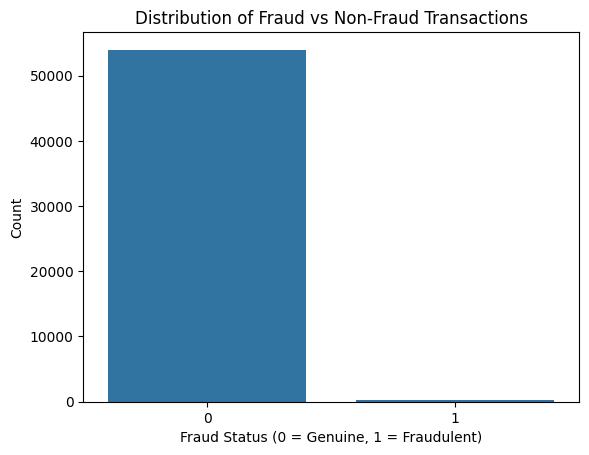

In [5]:
sns.countplot(x = 'Fraud', data = fraud_train)
plt.title('Distribution of Fraud vs Non-Fraud Transactions')
plt.xlabel('Fraud Status (0 = Genuine, 1 = Fraudulent)')
plt.ylabel('Count')
plt.show()


::: {.quarto-figure-caption}
Figure 1. Bar plot showing the distribution of fraudulent versus genuine transactions. The dataset is highly imbalanced, with fraudulent transactions making up a very small proportion of the total, highlighting the need for careful model evaluation metrics beyond simple accuracy.

:::

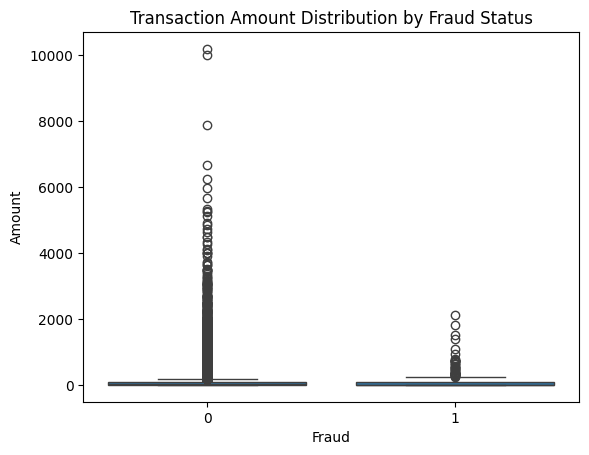

In [6]:
sns.boxplot(x = 'Fraud', y = 'Amount', data = fraud_train)
plt.title('Transaction Amount Distribution by Fraud Status')
plt.show()


:::{.quarto-figure-caption}
Figure 2. Boxplot of transaction amounts grouped by fraud status. Fraudulent transactions tend to have slightly lower or moderate amounts on average, though some high-value outliers are present. This suggests that transaction amount alone is not a strong discriminator but may contribute in combination with other features.

:::

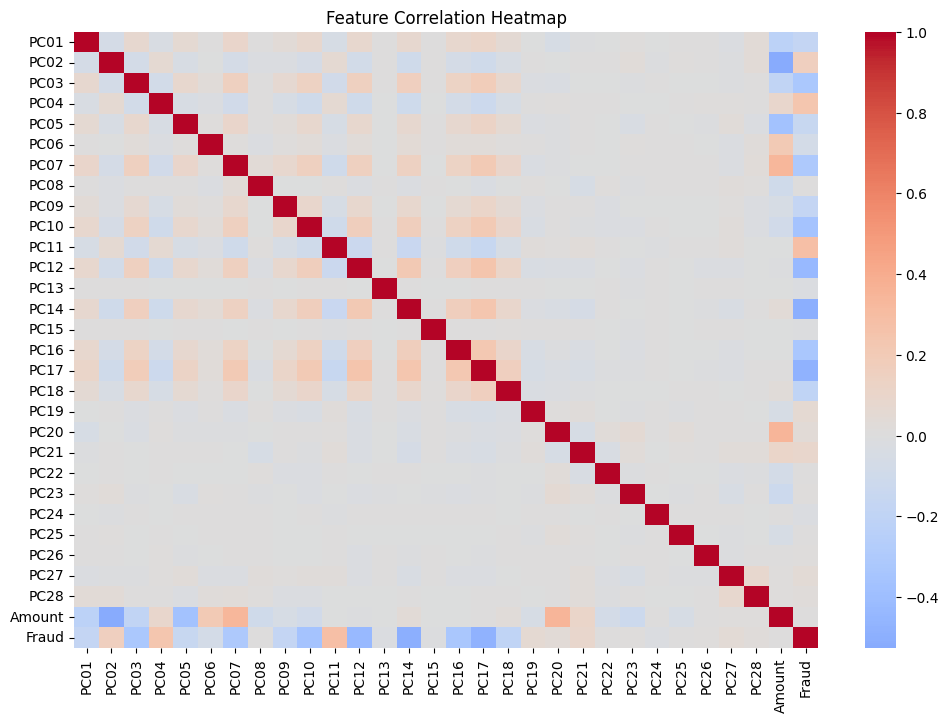

In [7]:
corr = fraud_train.corr()
plt.figure(figsize = (12, 8))
sns.heatmap(corr, cmap = 'coolwarm', center = 0)
plt.title('Feature Correlation Heatmap')
plt.show()

:::{.quarto-figure-caption}
Figure 3. Correlation heatmap of all features in the training dataset. As expected from PCA-transformed components, most principal components show minimal correlation with each other, confirming orthogonality, while the `Amount` variable exhibits weak correlations with several components and the `Fraud` label.

:::

### Models

To prepare the data for model development, the dataset was divided into feature variables (X) and the target variable (y). The target variable represents whether a transaction is fraudulent (1) or genuine (0), while the feature variables serve as predictors.

For preprocessing, two transformation pipelines were constructed. The numeric pipeline uses a SimpleImputer with the median strategy to handle missing values, followed by a StandardScaler to standardize the numerical features. The categorical pipeline applies a SimpleImputer with the most frequent strategy and a OneHotEncoder to encode categorical variables. These pipelines were then combined using a ColumnTransformer, which applies the appropriate transformations.

Numeric and categorical features were identified using the select_dtypes method but since this dataset contains only numerical variables, the categorical pipeline is unused. The combined preprocessor was subsequently fitted and applied to the training data before being integrated into a full modeling pipeline with a DecisionTreeClassifier.


```
X_train = fraud_train.drop('Fraud', axis = 1)
y_train = fraud_train['Fraud']

X_test = fraud_test.drop('Fraud', axis = 1)
y_test = fraud_test['Fraud']

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'median'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features))
```

In [8]:
X_train = fraud_train.drop('Fraud', axis = 1)
y_train = fraud_train['Fraud']

X_test = fraud_test.drop('Fraud', axis = 1)
y_test = fraud_test['Fraud']

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'median'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features))

To make the model, a Decision Tree Classifier was defined as an estimator since it is a simple, yet effective classifier and is easily interperatable due to its straightforward nature. `make_pipeline` was used to apply the preprocessing steps to the classifier.

This classifier was then used to return a model using `GridSearchCV` to perform an exhaustive search over hyperparameters, optimizing the maximum depth, minimum sample leaves, maximum number of features, and the splitter used for the classifier. The resulting best combination of parameters was then used to generate predictions and evaluate model performance on unseen data.

```
dec_tree = make_pipeline(preprocessor, DecisionTreeClassifier())

param_grid = {
    'decisiontreeclassifier__splitter': ['best'],  
    'decisiontreeclassifier__max_depth': [1, 2, 3, None],
    'decisiontreeclassifier__min_samples_leaf' : [1, 5],
    'decisiontreeclassifier__max_features' : [None, 'sqrt']
}

md = GridSearchCV(
    dec_tree, 
    param_grid, 
    cv = 3,
    scoring = 'recall'
)
md.fit(X_train, y_train)
```

In [9]:
dec_tree = make_pipeline(preprocessor, DecisionTreeClassifier())

param_grid = {
    'decisiontreeclassifier__splitter': ['best'],  
    'decisiontreeclassifier__max_depth': [1, 2, 3, None],
    'decisiontreeclassifier__min_samples_leaf' : [1, 5],
    'decisiontreeclassifier__max_features' : [None, 'sqrt']
}

md = GridSearchCV(
    dec_tree, 
    param_grid, 
    cv = 3,
    scoring = 'recall'
)
md.fit(X_train, y_train)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'decisiontreeclassifier__max_depth': [1, 2, ...], 'decisiontreeclassifier__max_features': [None, 'sqrt'], 'decisiontreeclassifier__min_samples_leaf': [1, 5], 'decisiontreeclassifier__splitter': ['best']}"
,scoring,'recall'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"


## Results

To evaluate model performance, we calculated the model’s accuracy and cross-validation scores, where accuracy measures the proportion of correctly classified samples, and cross-validation scores gauges  the model’s consistency and generalizability across different subsets of the training data. 

The precision and recall scores of the model were also calculated, providing deeper insight into its predictive reliability. Precision quantifies how many of the predicted positive cases were actually positive, reflecting the model’s ability to avoid false positives. Recall, on the other hand, measures how many of the actual positive cases were correctly identified, highlighting the model’s sensitivity to true positives. 

```
y_pred = md.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
p_score = precision_score(y_test, y_pred)
r_score = recall_score(y_test, y_pred)

scores = cross_val_score(md.best_estimator_, X_train, y_train, cv = 5)
mean_cv_acc = scores.mean()

print('accuracy_score for model: ' + str(acc_score) + '\n'
      + 'precision score for model: ' + str(p_score) + '\n'
      + 'recall score for model: ' + str(r_score) + '\n'
      + 'Mean CV accuracy: ' + str(mean_cv_acc))
```

In [10]:
y_pred = md.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
p_score = precision_score(y_test, y_pred)
r_score = recall_score(y_test, y_pred)

scores = cross_val_score(md.best_estimator_, X_train, y_train, cv = 5)
mean_cv_acc = scores.mean()

print('accuracy_score for model: ' + str(acc_score) + '\n'
      + 'precision score for model: ' + str(p_score) + '\n'
      + 'recall score for model: ' + str(r_score) + '\n'
      + 'Mean CV accuracy: ' + str(mean_cv_acc))

accuracy_score for model: 0.996904709263763
precision score for model: 0.7283950617283951
recall score for model: 0.7468354430379747
Mean CV accuracy: 0.9972916233176183


We can also visualize our model performance using a confusion matrix.

<Figure size 1500x1100 with 0 Axes>

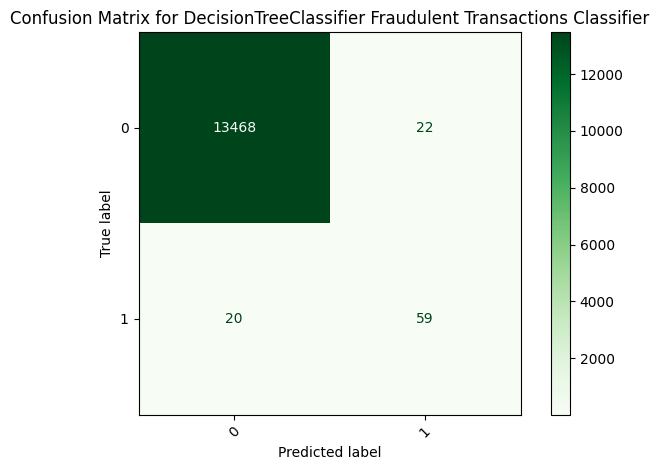

In [11]:
plt.figure(figsize = (15, 11))
ConfusionMatrixDisplay.from_estimator(md, X_test, y_test, cmap = "Greens", xticks_rotation = 45)
plt.title("Confusion Matrix for DecisionTreeClassifier Fraudulent Transactions Classifier", fontsize = 12)
plt.tight_layout()
plt.show()

:::{.quarto-figure-caption}
Figure 4. Confusion matrix of actual vs. predicted fraudulent transactions, showing that the model correctly identified the vast majority of legitimate transactions (true negatives = 13,485) and most fraudulent ones (true positives = 64), with only a few misclassifications (5 false positives and 15 false negatives).

:::

## Discussion

### Would I deploy this model?
I would <b> NOT </b> deploy this model. The current model at this point in time shouldn't be deployed without better hyperparameter tuning, as well as more extensive model training.

The models current performance measured by the accuracy, precision, recall, and cross validation scores, though are relatively ok, can be better, and the processes to do so can be much more sound. 

### Risks avoided by not using this model:
- Classification errors/confusion in the model (eg., problems highlighted in Figure 3)
- The scale of real-world data is much greater than the small subset of data used in this model and variability is a much bigger risk in this scenario
    - Unclear as to weather or not DecisionTreeClassifier model could scale to that level
- This model true performance isn't being gauged on live data  

### Potential improvements
- Try other classifiers to create our model 
    - This could help us not only improve performance of the model on not just this data, but also  data of greater magnitudes 
- Fine-tune more hyperparameters on our model to further optimize potential model performance
    - Do a deeper search through multiple hyperparameter options
- Add/create new features to be used for predicting the target

## Conclusion

Though our model performs nicely, it could always be improved upon to be able to scale much better and be much more reliable. It's decent accuracy, precision, recall, and cross validation scores helps us know that we're at least moving in the right direction towards an even better model to be put into practical use. 